# **Experiment Notebook**

## Climate Comfort Index — Experiment 1: Regularised Linear Baseline

In [1]:
# Do not modify this code
!pip install -q utstd

from utstd.ipyrenders import *

In [2]:
# Do not modify this code
import warnings
warnings.simplefilter(action='ignore')

In [3]:
import pandas as pd

pd.__version__

'2.2.3'

---
## Student Information

In [4]:
student_name = "Abhishek Chopda"
student_id = "25611094"

In [5]:
# Do not modify this code
print_tile(size="h1", key='student_name', value=student_name)

In [6]:
# Do not modify this code
print_tile(size="h1", key='student_id', value=student_id)

---
## 0. Python Packages

In [7]:
# Standard data science stack.
from pathlib import Path

import joblib
import matplotlib.pyplot as plt
import numpy as np
import seaborn as sns

# Project toolkit, published to TestPyPI as `mlkit-aby`. All reusable
# functionality lives here so that this notebook contains only the
# decisions specific to this experiment.
from mlkit_aby.helpers import (
    eda,
    features,
    importance,
    modeling,
    targets,
    timeseries,
    visualization,
    weather,
)

# Project configuration: paths, modelling windows and forecast horizons.
from weather_intelligence.config import (
    CCI_HORIZONS,
    CCI_MODELS_DIR,
    CCI_TRAIN_START,
    PROCESSED_DATA_DIR,
    RAW_WEATHER_FILE,
)

from sklearn.linear_model import Ridge

pd.set_option("display.max_columns", 120)
sns.set_theme(style="whitegrid")

# Fixed throughout so that every result in this notebook is reproducible.
RANDOM_STATE = 42

print("mlkit-aby modules loaded")
print("Forecast horizons:", CCI_HORIZONS)
print("Modelling window starts:", CCI_TRAIN_START)

2026-09-18 14:55:28.046 | INFO     | weather_intelligence.config:<module>:11 - PROJ_ROOT path is: /Users/aby/UTS/AMLA - Sem 4/Assign 2/sydney-weather-intelligence


mlkit-aby modules loaded
Forecast horizons: [1, 2, 3]
Modelling window starts: 2015-01-01


In [8]:
import sys, mlkit_aby
print(sys.executable)
print(mlkit_aby.__version__)

/Users/aby/UTS/AMLA - Sem 4/Assign 2/sydney-weather-intelligence/.venv/bin/python
0.3.0


---
## A. Project Description

In [9]:
business_use_case_description = """
Open Meteo is adding predictive intelligence to its weather platform. This
experiment builds the first of two services: a forecast of the Climate
Comfort Index (CCI) for Sydney, one, two and three days ahead.

The CCI condenses temperature, humidity, wind, cloud cover and rainfall into
a single 0-100 score describing how suitable a day is for being outdoors.
Raw weather variables already exist in the platform; what does not exist is
a single forward-looking number that a non-expert can act on. A tour
operator does not want five forecast variables, they want to know whether
Thursday is worth running the harbour cruise.

The service must predict the CCI of a future day using only information
available today, and expose that prediction through a REST API.
"""

In [10]:
# Do not modify this code
print_tile(size="h3", key='business_use_case_description', value=business_use_case_description)

In [11]:
business_objectives = """
The objective is a comfort forecast accurate enough to support real
scheduling decisions three days ahead.

Accurate predictions let operators commit earlier: staff are rostered,
stock is ordered and marketing is scheduled against a reliable signal
rather than a guess, and customers receive advice they come to trust.

Inaccurate predictions carry asymmetric costs. Predicting comfort that does
not arrive is the more damaging error: customers are brought outdoors into
unpleasant conditions, refunds follow, and trust in the service is lost.
Predicting discomfort that does not arrive is cheaper, forgoing revenue on
a day that turned out fine. This asymmetry is not captured by a symmetric
error metric such as RMSE, and is noted as a limitation of this experiment.

Errors also matter more in some parts of the range than others. Confusing a
CCI of 82 with 78 moves a day from "excellent" to "comfortable" and changes
very little. Confusing 62 with 58 moves it across the boundary between
"comfortable" and "moderate", which may change a decision.
"""

In [12]:
# Do not modify this code
print_tile(size="h3", key='business_objectives', value=business_objectives)

In [13]:
stakeholders_expectations_explanations = """
Predictions are consumed through a REST endpoint that accepts a date and
returns the CCI for the following three days.

Direct users are the developers integrating the endpoint into scheduling
tools, dashboards and consumer applications. They need stable response
shapes, honest error handling and transparency about model performance,
which the /model-metadata endpoint provides.

Indirectly affected are the operators making decisions on the forecast —
outdoor venues, event organisers, tourism operators, councils scheduling
maintenance — and the members of the public who act on advice derived from
it.

Expectations are shaped by a well-understood reality: everyone knows
weather forecasts are imperfect, and tolerance for error grows with the
horizon. A one-day forecast is expected to be dependable; a three-day
forecast is expected to be indicative. The service should be honest about
that gradient rather than presenting all three horizons as equally certain.
"""

In [14]:
# Do not modify this code
print_tile(size="h3", key='stakeholders_expectations_explanations', value=stakeholders_expectations_explanations)

---
## C. Data Understanding

### C.1   Load Raw Data

In [15]:
# Hourly observations for Sydney (latitude -33.8688, longitude 151.2093),
# retrieved from the Open-Meteo Historical Weather API.
#
# If this file does not exist, regenerate it by running:
#     uv run python -m weather_intelligence.dataset
hourly = pd.read_csv(RAW_WEATHER_FILE, parse_dates=["time"])

print(f"{len(hourly):,} hourly observations")
print(f"{hourly['time'].min()} to {hourly['time'].max()}")
hourly.head()

227,928 hourly observations
2000-01-01 00:00:00 to 2025-12-31 23:00:00


,time,temperature_2m,relative_humidity_2m,wind_speed_10m,cloud_cover,precipitation,wind_gusts_10m,snowfall
0,2000-01-01 00:00:00,16.2,66,15.5,91,0.0,30.6,0.0
1,2000-01-01 01:00:00,15.9,69,15.1,97,0.0,30.2,0.0
2,2000-01-01 02:00:00,15.6,70,15.0,98,0.0,29.9,0.0
3,2000-01-01 03:00:00,15.5,71,15.0,98,0.0,29.2,0.0
4,2000-01-01 04:00:00,15.5,71,15.5,99,0.0,29.5,0.0


In [16]:
# Confirm the raw feed is complete before anything is derived from it.
eda.dataset_overview(hourly)

,rows,columns,duplicate_rows,missing_values
0,227928,8,0,0


In [17]:
eda.missing_summary(hourly)

,missing_count,missing_percentage
time,0,0.0
temperature_2m,0,0.0
relative_humidity_2m,0,0.0
wind_speed_10m,0,0.0
cloud_cover,0,0.0
precipitation,0,0.0
wind_gusts_10m,0,0.0
snowfall,0,0.0


### C.2 Define Target variable

In [18]:
# The CCI formula is defined on daily weather values, so the hourly feed is
# aggregated first. The aggregation applied to each variable is a deliberate
# choice rather than a blanket average:
weather.TARGET_DAILY_AGGREGATIONS

{'temperature_2m': ('temperature_2m', 'mean'),
 'relative_humidity_2m': ('relative_humidity_2m', 'mean'),
 'wind_speed_10m': ('wind_speed_10m', 'mean'),
 'cloud_cover': ('cloud_cover', 'mean'),
 'precipitation': ('precipitation', 'sum'),
 'wind_gusts_10m': ('wind_gusts_10m', 'max'),
 'snowfall': ('snowfall', 'sum')}

In [19]:
daily = weather.aggregate_to_daily(hourly)

print(f"{len(daily):,} daily observations")
daily.head()

9,497 daily observations


,date,temperature_2m,relative_humidity_2m,wind_speed_10m,cloud_cover,precipitation,wind_gusts_10m,snowfall
0,2000-01-01,17.391667,65.875000,16.004167,97.500000,0.0,46.8,0.0
1,2000-01-02,17.500000,83.875000,10.037500,77.208333,2.8,34.6,0.0
2,2000-01-03,19.775000,75.625000,9.350000,36.833333,0.1,44.6,0.0
3,2000-01-04,22.887500,66.041667,12.375000,51.375000,2.2,55.1,0.0
4,2000-01-05,19.179167,51.666667,12.400000,34.250000,0.0,47.2,0.0


In [20]:
target_definition_explanations = """
The target is the Climate Comfort Index, a 0 to 100 score built from five
component scores. It is a regression target, predicted one, two and three days
ahead.

The main decision is the order of operations. Open-Meteo gives hourly data but
the index is defined per day, so the weather is aggregated to daily values
before the formula is applied. The formulas use MIN, MAX and ABS, so applying
them hourly and averaging afterwards gives a different answer. The constants
settle it: precipitation is divided by 20, which is a sensible daily total in
millimetres but almost never an hourly rate. The subject coordinator confirmed
this reading.

Temperature, humidity, wind and cloud use the daily mean because comfort is
about typical conditions, while rainfall uses the daily total. Using means
hides variation within the day, which is recovered as features in section F.
"""


In [21]:
# Do not modify this code
print_tile(size="h3", key='target_definition_explanations', value=target_definition_explanations)

### C.3 Create Target variable

In [22]:
# Component scores are computed separately from the index itself, so that
# the contribution of each can be inspected rather than taken on trust.
cci_components = targets.climate_comfort_components(daily)
cci_components.describe().T

,count,mean,std,min,25%,50%,75%,max
temperature_score,9497.0,0.749097,0.175627,0.281250,0.595208,0.773542,0.908750,1.0
humidity_score,9497.0,0.557172,0.198765,0.079167,0.405000,0.540000,0.696667,1.0
wind_score,9497.0,0.915779,0.078579,0.315313,0.890208,0.936667,0.970000,1.0
cloud_score,9497.0,0.526207,0.300381,0.000000,0.283750,0.535833,0.780417,1.0
rain_score,9497.0,0.907493,0.206476,0.000000,0.930000,1.000000,1.000000,1.0


In [23]:
daily["cci"] = targets.climate_comfort_index(daily)

target_name = "cci"

daily[["date", "temperature_2m", "relative_humidity_2m", "wind_speed_10m",
       "cloud_cover", "precipitation", "cci"]].head()

,date,temperature_2m,relative_humidity_2m,wind_speed_10m,cloud_cover,precipitation,cci
0,2000-01-01,17.391667,65.875000,16.004167,97.500000,0.0,68.708854
1,2000-01-02,17.500000,83.875000,10.037500,77.208333,2.8,64.879688
2,2000-01-03,19.775000,75.625000,9.350000,36.833333,0.1,80.012500
3,2000-01-04,22.887500,66.041667,12.375000,51.375000,2.2,81.783333
4,2000-01-05,19.179167,51.666667,12.400000,34.250000,0.0,88.359375


### C.4 Explore Target variable

In [24]:
daily["cci"].describe()

count    9497.000000
mean       72.604010
std        10.154392
min        28.634375
25%        67.090104
50%        73.615104
75%        79.393229
max        98.889583
Name: cci, dtype: float64

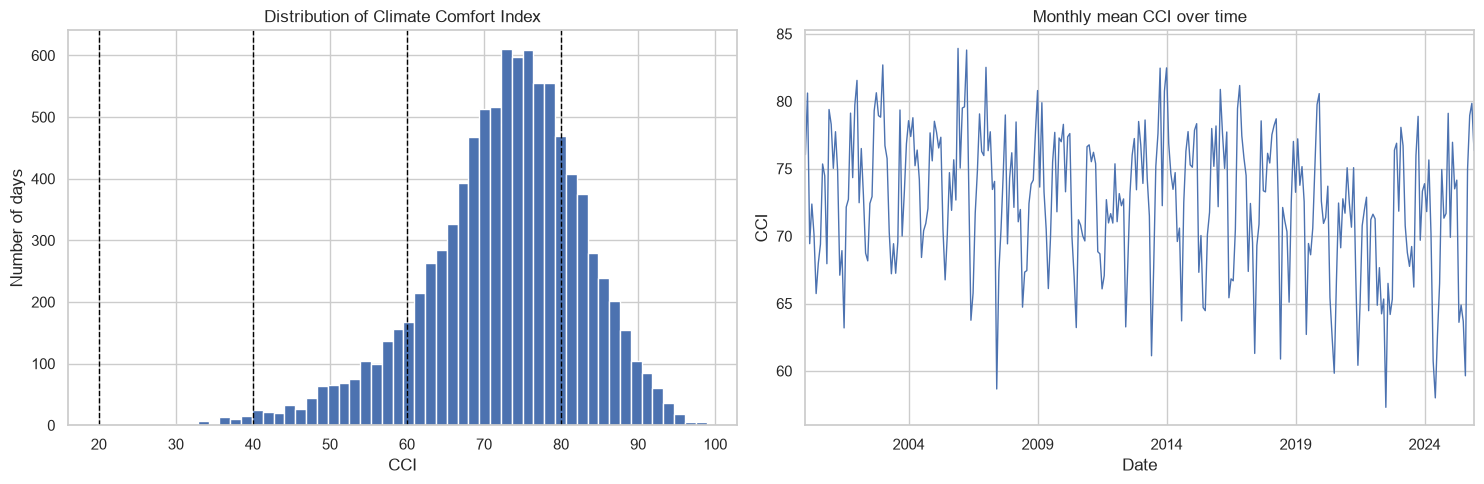

In [25]:
fig, axes = plt.subplots(1, 2, figsize=(15, 5))

axes[0].hist(daily["cci"], bins=50, edgecolor="white")
axes[0].set_title("Distribution of Climate Comfort Index")
axes[0].set_xlabel("CCI")
axes[0].set_ylabel("Number of days")

# Interpretation band boundaries from the project specification.
for boundary in [20, 40, 60, 80]:
    axes[0].axvline(boundary, linestyle="--", color="black", linewidth=1)

daily.set_index("date")["cci"].resample("ME").mean().plot(ax=axes[1], linewidth=1)
axes[1].set_title("Monthly mean CCI over time")
axes[1].set_xlabel("Date")
axes[1].set_ylabel("CCI")

plt.tight_layout()
plt.show()

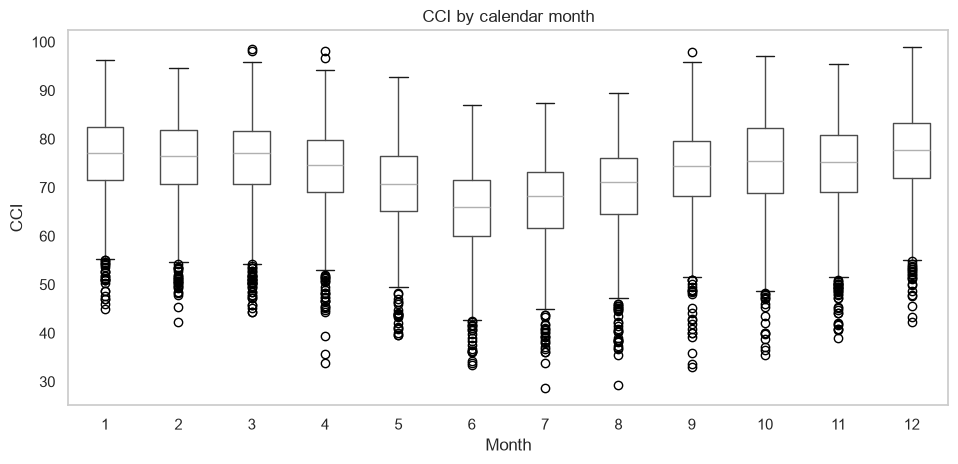

month
1     76.4
2     75.4
3     75.3
4     73.8
5     70.0
6     65.0
7     66.7
8     69.6
9     73.6
10    74.6
11    74.0
12    76.9
Name: cci, dtype: float64

In [26]:
# Seasonality is the dominant structure in the target, so it is worth
# quantifying rather than only eyeballing the time series.
by_month = daily.assign(month=daily["date"].dt.month).groupby("month")["cci"]

fig, ax = plt.subplots(figsize=(11, 5))
daily.assign(month=daily["date"].dt.month).boxplot(
    column="cci", by="month", ax=ax, grid=False
)
ax.set_title("CCI by calendar month")
ax.set_xlabel("Month")
ax.set_ylabel("CCI")
plt.suptitle("")
plt.show()

by_month.mean().round(1)

In [27]:
# How much of the index's variation does each component drive? A component
# that never varies cannot help a model discriminate between days.
component_summary = pd.DataFrame({
    "mean": cci_components.mean(),
    "std": cci_components.std(),
    "min": cci_components.min(),
    "max": cci_components.max(),
    "weight": pd.Series(targets.CCI_WEIGHTS),
})
component_summary["weighted_std"] = component_summary["std"] * component_summary["weight"]
component_summary.sort_values("weighted_std", ascending=False).round(3)

,mean,std,min,max,weight,weighted_std
temperature_score,0.749,0.176,0.281,1.0,0.35,0.061
cloud_score,0.526,0.300,0.000,1.0,0.15,0.045
humidity_score,0.557,0.199,0.079,1.0,0.20,0.040
rain_score,0.907,0.206,0.000,1.0,0.15,0.031
wind_score,0.916,0.079,0.315,1.0,0.15,0.012


In [28]:
target_distribution_explanations = """
The CCI is roughly normal, centred near 71 with a standard deviation of about
11 and ranging from 29 to 98. No day in 26 years scores below 20, so the worst
band is empty. Sydney's climate is mild and the index reflects that.

There is a clear seasonal pattern, with comfort highest in the shoulder seasons
and lowest in mid winter. It would be easy to overstate it: the spread within
any month is much larger than the difference between months, and section J.4
shows a baseline using only the day of the year reaches an R squared of about
0.05.

Mean CCI has also drifted down about four points since 2000, from 74 to 70,
which is why the model is trained on 2015 onwards rather than the full record.
"""


In [29]:
# Do not modify this code
print_tile(size="h3", key='target_distribution_explanations', value=target_distribution_explanations)

### C.5 Explore Feature of Interest `temperature_2m`

In [30]:
# Daily mean temperature is the largest single contributor to the index, so
# its behaviour largely determines the target's behaviour.
daily["temperature_2m"].describe()

count    9497.000000
mean       17.475364
std         4.128802
min         7.625000
25%        13.908333
50%        17.600000
75%        20.787500
max        30.904167
Name: temperature_2m, dtype: float64

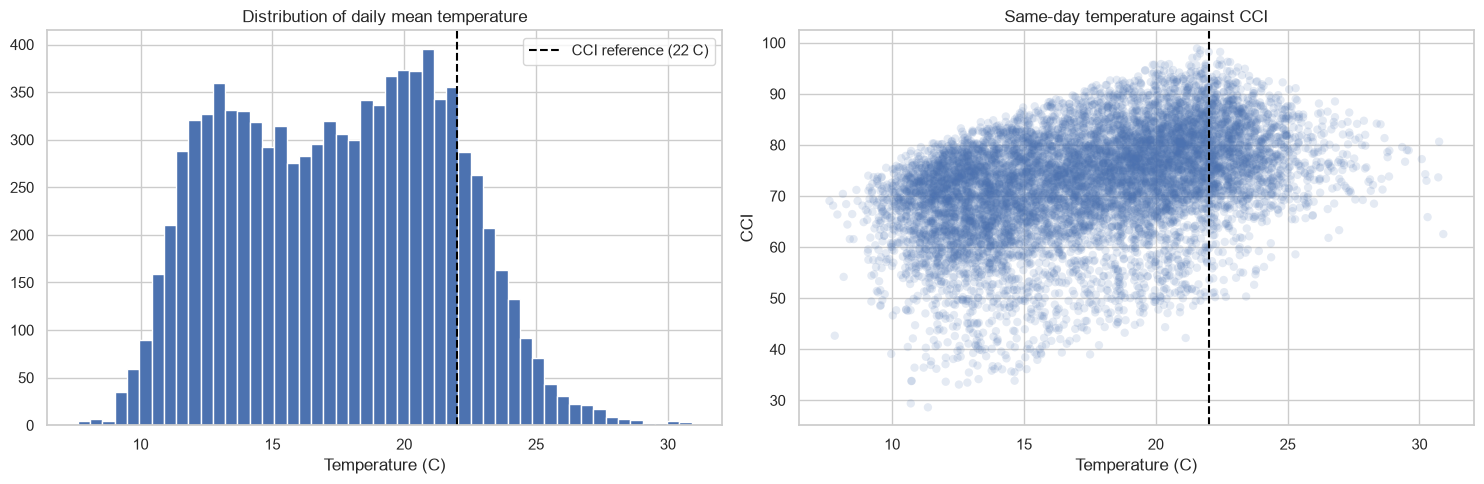

In [31]:
fig, axes = plt.subplots(1, 2, figsize=(15, 5))

axes[0].hist(daily["temperature_2m"], bins=50, edgecolor="white")
axes[0].axvline(22, linestyle="--", color="black", label="CCI reference (22 C)")
axes[0].set_title("Distribution of daily mean temperature")
axes[0].set_xlabel("Temperature (C)")
axes[0].legend()

axes[1].scatter(daily["temperature_2m"], daily["cci"], alpha=0.15, edgecolor="none")
axes[1].axvline(22, linestyle="--", color="black")
axes[1].set_title("Same-day temperature against CCI")
axes[1].set_xlabel("Temperature (C)")
axes[1].set_ylabel("CCI")

plt.tight_layout()
plt.show()

In [32]:
feature_1_insights = """
Daily mean temperature ranges from about 6 C to 32 C and averages 18 C, four
degrees below the 22 C the formula treats as ideal. Sydney is therefore
slightly cool relative to the index, and most of the temperature penalty comes
from days that are too cold.

The scatter shows the upside down V the formula implies, but an uneven one:
there are many cool days and few very hot ones. Because the relationship is
close to a straight line across most of the observed range, a linear model is a
reasonable starting point. The vertical spread at any temperature, where a 20 C
day can score from 45 to 90, is the contribution of the other four components.
"""


In [33]:
# Do not modify this code
print_tile(size="h3", key='feature_1_insights', value=feature_1_insights)

### C.6 Explore Feature of Interest `cloud_cover`

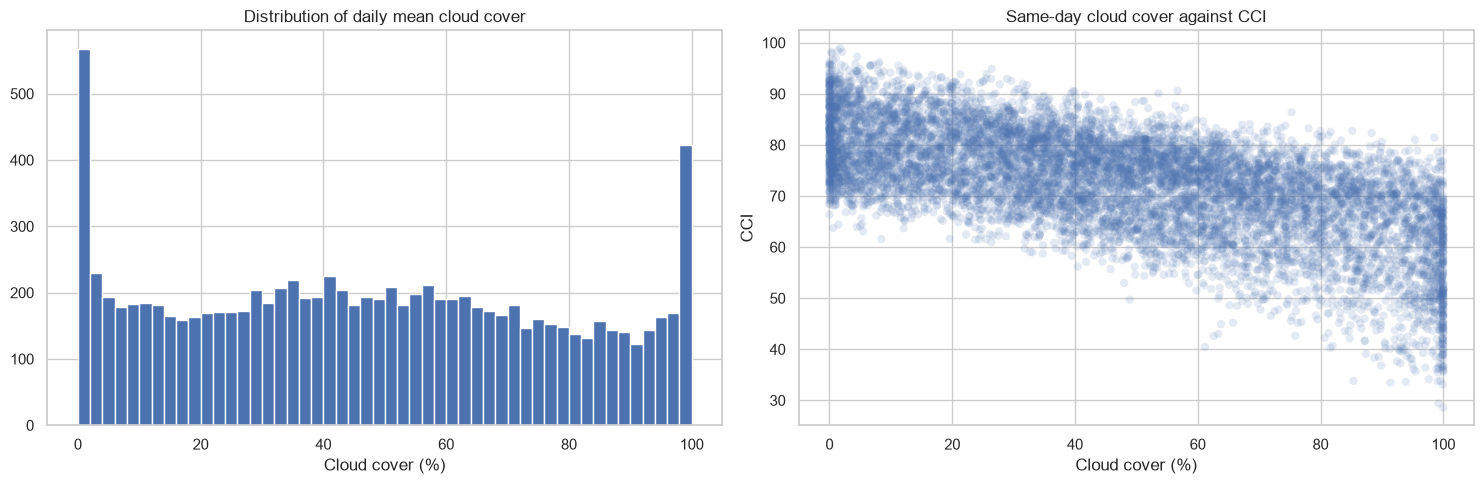

count    9497.000000
mean       47.379286
std        30.038081
min         0.000000
25%        21.958333
50%        46.416667
75%        71.625000
max       100.000000
Name: cloud_cover, dtype: float64

In [34]:
fig, axes = plt.subplots(1, 2, figsize=(15, 5))

axes[0].hist(daily["cloud_cover"], bins=50, edgecolor="white")
axes[0].set_title("Distribution of daily mean cloud cover")
axes[0].set_xlabel("Cloud cover (%)")

axes[1].scatter(daily["cloud_cover"], daily["cci"], alpha=0.15, edgecolor="none")
axes[1].set_title("Same-day cloud cover against CCI")
axes[1].set_xlabel("Cloud cover (%)")
axes[1].set_ylabel("CCI")

plt.tight_layout()
plt.show()

daily["cloud_cover"].describe()

In [35]:
feature_2_insights = """
Cloud cover spans nearly the full 0-100% range and is broadly spread rather
than concentrated, which makes it genuinely informative: a feature that
varies widely can discriminate between days in a way a near-constant one
cannot.

Its relationship with CCI is negative and close to linear, which follows
directly from the component formula, where the cloud score is a straight
linear function of cover with no clipping in the observed range. Of the five
components this is the best behaved from a linear model's point of view.

Cloud cover is also correlated with the other components, most obviously
rainfall — wet days are cloudy days. That correlation is useful for
prediction but means the coefficients of cloud and rain terms should not be
read as independent causal effects, since the two carry overlapping
information.
"""

In [36]:
# Do not modify this code
print_tile(size="h3", key='feature_2_insights', value=feature_2_insights)

### C.7 Explore Feature of Interest `precipitation`

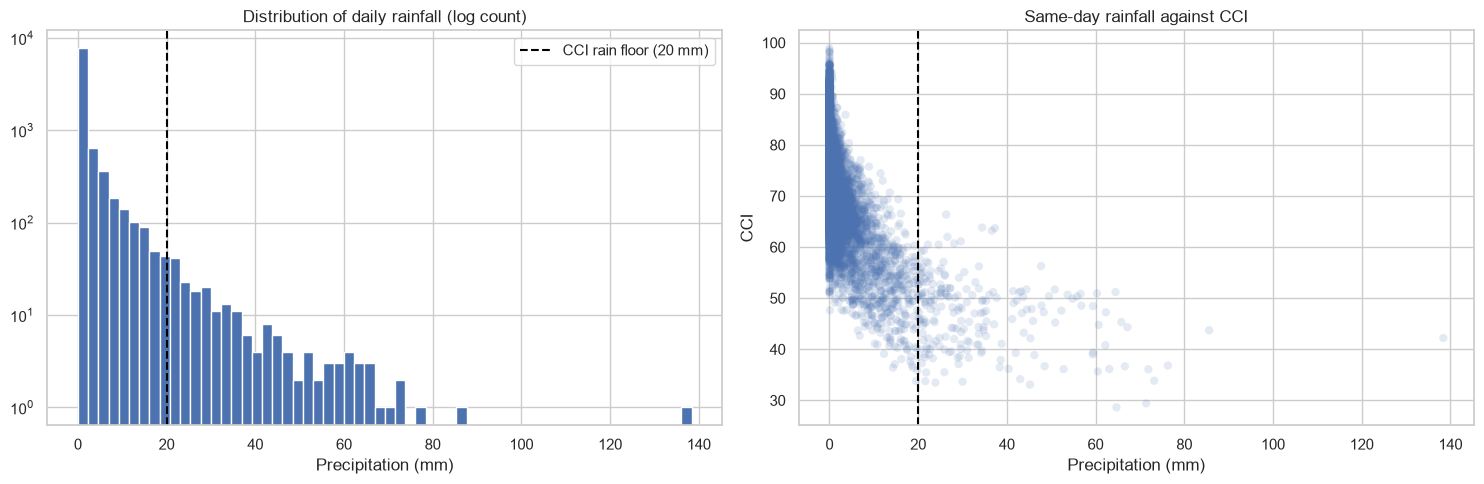

Days with no rain: 50.7%
Days above the 20 mm floor: 2.2%


count    9497.000000
mean        2.159324
std         6.148343
min         0.000000
25%         0.000000
50%         0.000000
75%         1.400000
max       138.400000
Name: precipitation, dtype: float64

In [37]:
fig, axes = plt.subplots(1, 2, figsize=(15, 5))

# Rainfall is heavily right skewed, so a log scale on the count axis is the
# only way to see the tail at all.
axes[0].hist(daily["precipitation"], bins=60, edgecolor="white")
axes[0].set_yscale("log")
axes[0].axvline(20, linestyle="--", color="black", label="CCI rain floor (20 mm)")
axes[0].set_title("Distribution of daily rainfall (log count)")
axes[0].set_xlabel("Precipitation (mm)")
axes[0].legend()

axes[1].scatter(daily["precipitation"], daily["cci"], alpha=0.15, edgecolor="none")
axes[1].axvline(20, linestyle="--", color="black")
axes[1].set_title("Same-day rainfall against CCI")
axes[1].set_xlabel("Precipitation (mm)")
axes[1].set_ylabel("CCI")

plt.tight_layout()
plt.show()

print("Days with no rain: {:.1%}".format((daily["precipitation"] == 0).mean()))
print("Days above the 20 mm floor: {:.1%}".format((daily["precipitation"] >= 20).mean()))
daily["precipitation"].describe()

In [38]:
feature_n_insights = """
Rainfall is the hardest variable to work with. Just over half of all days record
no rain, and the rest fall away steeply to a maximum of 138 mm. The median is
zero while the mean is about 3 mm, so most of the data sits on one value, which
a linear model handles poorly.

Its effect on the CCI is a ramp that stops: above 20 mm the rain score is zero
and further rain changes nothing. About 2% of days are in that region. A
straight line cannot represent a relationship that flattens, so the model is
expected to under predict comfort on the wettest days. This is the clearest
reason to try a tree based model in the next experiment.
"""


In [39]:
# Do not modify this code
print_tile(size="h3", key='feature_n_insights', value=feature_n_insights)

### C.n Explore Feature of Interest

> Further variables (humidity, wind speed) follow the same pattern and are examined through the correlation analysis in section D rather than individually here.

In [40]:
# A compact view of the remaining candidate variables against the target,
# rather than repeating the full treatment for each.
candidate_variables = [
    "temperature_2m", "relative_humidity_2m", "wind_speed_10m",
    "cloud_cover", "precipitation", "wind_gusts_10m",
]
eda.numerical_summary(daily[candidate_variables]).round(2)

,count,mean,std,min,25%,50%,75%,max
temperature_2m,9497.0,17.48,4.13,7.62,13.91,17.60,20.79,30.90
relative_humidity_2m,9497.0,71.70,10.86,23.88,65.04,73.00,79.75,96.04
wind_speed_10m,9497.0,11.39,4.39,3.31,8.15,10.48,13.80,37.39
cloud_cover,9497.0,47.38,30.04,0.00,21.96,46.42,71.62,100.00
precipitation,9497.0,2.16,6.15,0.00,0.00,0.00,1.40,138.40
wind_gusts_10m,9497.0,39.42,12.39,12.60,31.00,38.50,46.40,102.20


---
## D. Feature Selection

### D.1 Approach "Correlation with the future target"

In [41]:
# The question is not which variables correlate with *today's* CCI — by
# construction they all do, since today's CCI is computed from them. The
# question is which of today's variables carry information about a *future*
# day's CCI. That is what a forecast actually needs.
horizon_correlations = {}

for h in CCI_HORIZONS:
    future_cci = daily["cci"].shift(-h)
    horizon_correlations[f"cci_h{h}"] = (
        daily[candidate_variables + ["cci"]].corrwith(future_cci)
    )

correlation_with_future = pd.DataFrame(horizon_correlations)
correlation_with_future["abs_h1"] = correlation_with_future["cci_h1"].abs()
correlation_with_future.sort_values("abs_h1", ascending=False).drop(columns="abs_h1").round(3)

,cci_h1,cci_h2,cci_h3
cci,0.605,0.376,0.289
relative_humidity_2m,-0.365,-0.203,-0.130
temperature_2m,0.340,0.310,0.309
cloud_cover,-0.320,-0.117,-0.039
precipitation,-0.270,-0.117,-0.064
wind_gusts_10m,0.111,0.107,0.100
wind_speed_10m,-0.014,-0.010,-0.015


In [42]:
feature_selection_1_insights = """
This approach ranks the daily variables by their correlation with the CCI one,
two and three days ahead, which is what the model has to predict.

Today's CCI is the strongest single predictor of tomorrow's at about 0.6.
Weather carries over from one day to the next, and this is a fair feature
rather than leakage, because today's CCI is calculated only from weather
already observed.

Every correlation weakens as the horizon grows, which means the three day model
will be harder than the one day model. Among the weather variables, humidity,
temperature and cloud cover carry the most, while rainfall correlates weakly
because rain is much less persistent than temperature.
"""


In [43]:
# Do not modify this code
print_tile(size="h3", key='feature_selection_1_insights', value=feature_selection_1_insights)

### D.2 Approach "Multicollinearity screening"

In [44]:
# Highly correlated inputs destabilise linear models: the fit can shift large
# offsetting coefficients between near-duplicate features, which makes the
# coefficients unreliable to interpret even when predictions are fine.
eda.find_highly_correlated_features(daily[candidate_variables], threshold=0.70)

,feature_1,feature_2,correlation
0,wind_speed_10m,wind_gusts_10m,0.836822


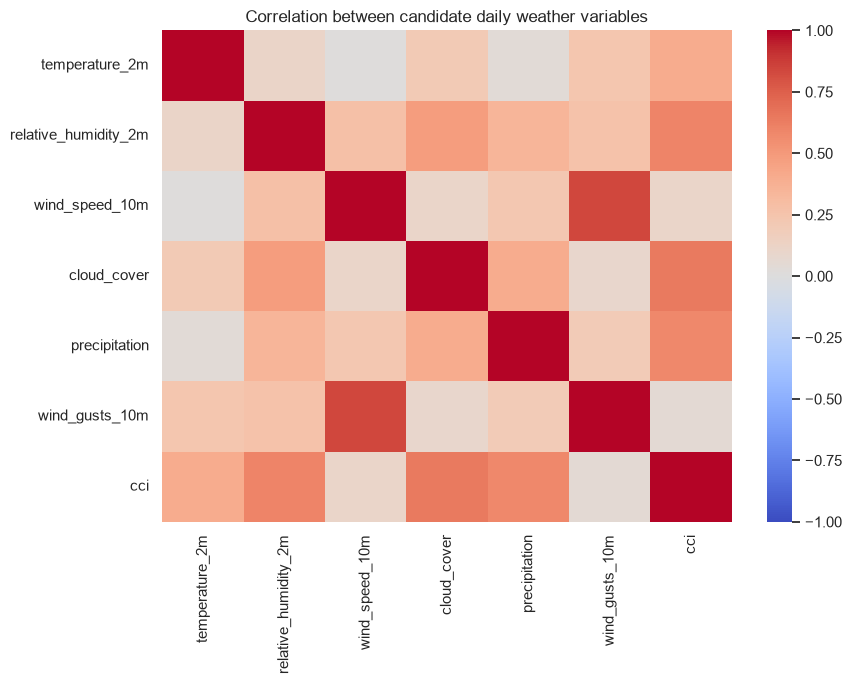

In [45]:
correlation_matrix = eda.calculate_correlation_matrix(daily[candidate_variables + ["cci"]])
visualization.plot_correlation_heatmap(
    correlation_matrix,
    figsize=(9, 7),
    title="Correlation between candidate daily weather variables",
)

In [46]:
feature_selection_2_insights = """
This approach checks whether any two variables carry the same information,
which matters because this experiment uses a linear model and linear models are
unstable when their inputs overlap.

Wind speed and wind gusts correlate strongly because they measure the same
thing at different statistics. Keeping both would split one effect across two
coefficients without adding information, so gusts are dropped and wind speed is
kept, since that is the variable the CCI formula uses.

Cloud cover, humidity and rainfall overlap more mildly and each contributes a
separate component to the index, so all three are kept. Ridge regression is
chosen partly for this reason, as its penalty stabilises the fit when inputs
share information.
"""


In [47]:
# Do not modify this code
print_tile(size="h3", key='feature_selection_2_insights', value=feature_selection_2_insights)

## D.z Final Selection of Features

In [48]:
# The five variables the CCI formula is built from, which are therefore the
# variables carrying direct information about it. Wind gusts are dropped as
# redundant with wind speed for this target.
features_list = [
    "temperature_2m",
    "relative_humidity_2m",
    "wind_speed_10m",
    "cloud_cover",
    "precipitation",
]

# Today's CCI is a legitimate and strong predictor of a future CCI, since it
# is computed only from weather already observed.
base_features = features_list + ["cci"]

base_features

['temperature_2m',
 'relative_humidity_2m',
 'wind_speed_10m',
 'cloud_cover',
 'precipitation',
 'cci']

In [49]:
feature_selection_explanations = """
The five variables in the CCI formula are kept, along with the CCI itself.

These variables do not merely correlate with the target, they define it. A
perfect three day forecast of the five would give a perfect CCI forecast by
construction, so the most direct way to predict the index is to track the
variables that make it up.

Wind gusts are dropped as a duplicate of wind speed, and snowfall is dropped
because it is zero on every day of the 26 year record and so cannot separate
one day from another.

These are base variables rather than final inputs. Section F builds lag,
rolling and calendar features from them.
"""


In [50]:
# Do not modify this code
print_tile(size="h3", key='feature_selection_explanations', value=feature_selection_explanations)

---
## E. Data Preparation

### E.1 Data Transformation: Missing value check

In [51]:
eda.missing_summary(daily)

,missing_count,missing_percentage
date,0,0.0
temperature_2m,0,0.0
relative_humidity_2m,0,0.0
wind_speed_10m,0,0.0
cloud_cover,0,0.0
precipitation,0,0.0
wind_gusts_10m,0,0.0
snowfall,0,0.0
cci,0,0.0


In [52]:
data_cleaning_1_explanations = """
The daily dataset contains no missing values in any column.

This is expected rather than lucky. Open-Meteo's historical archive is a
reanalysis product: observations are assimilated into a physical model that
produces a complete, gap-free grid. There are no station outages or
unreported days to handle.

The check is still performed and documented, for two reasons. Any missing
hourly value would propagate silently into a daily aggregate — pandas
aggregation skips missing values by default, so a day with only six reported
hours would produce a mean computed from six hours while looking identical
to a complete one. Confirming completeness at the source rules that out. It
also establishes that missing values appearing later in the pipeline must
have been introduced by the feature engineering step, where they are
expected and handled deliberately, rather than inherited from the data.
"""

In [53]:
# Do not modify this code
print_tile(size="h3", key='data_cleaning_1_explanations', value=data_cleaning_1_explanations)

### E.2 Data Transformation: Calendar continuity check

In [54]:
# Lag and rolling features assume consecutive rows are consecutive days. If
# a date were missing, a "1 day lag" would silently reach further back.
expected_dates = pd.date_range(daily["date"].min(), daily["date"].max(), freq="D")
missing_dates = expected_dates.difference(daily["date"])

print(f"Expected days: {len(expected_dates):,}")
print(f"Observed days: {len(daily):,}")
print(f"Missing days:  {len(missing_dates)}")
print(f"Duplicate dates: {daily['date'].duplicated().sum()}")

Expected days: 9,497
Observed days: 9,497
Missing days:  0
Duplicate dates: 0


In [55]:
data_cleaning_2_explanations = """
The dates run from 2000 to 2025 with no gaps and no duplicates.

This matters more than it appears. Every lag and rolling feature in section F
shifts rows rather than dates. If one day were missing from the middle of the
record, a column labelled yesterday would actually be showing the day before
that, and a seven day average would cover eight calendar days.

That kind of error raises no warning and produces no missing values, it simply
makes some rows quietly wrong. Since the dates are complete, shifting rows is
safe here. Had there been gaps, the frame would first have needed reindexing
onto a complete date range so the gaps became visible.
"""


In [56]:
# Do not modify this code
print_tile(size="h3", key='data_cleaning_2_explanations', value=data_cleaning_2_explanations)

### E.3 Data Transformation: Physical plausibility check

In [57]:
# Reanalysis output can still contain physically impossible values. Checking
# the bounds is cheap and catches unit errors and corrupt records.
plausibility = pd.DataFrame({
    "min": daily[candidate_variables].min(),
    "max": daily[candidate_variables].max(),
})
plausibility["plausible_range"] = [
    "-10 to 50 C", "0 to 100 %", "0 to 150 km/h",
    "0 to 100 %", "0 to 500 mm", "0 to 250 km/h",
]

print("CCI within its defined 0-100 range:",
      bool(daily["cci"].between(0, 100).all()))
plausibility

CCI within its defined 0-100 range: True


,min,max,plausible_range
temperature_2m,7.625000,30.904167,-10 to 50 C
relative_humidity_2m,23.875000,96.041667,0 to 100 %
wind_speed_10m,3.308333,37.387500,0 to 150 km/h
cloud_cover,0.000000,100.000000,0 to 100 %
precipitation,0.000000,138.400000,0 to 500 mm
wind_gusts_10m,12.600000,102.200000,0 to 250 km/h


In [58]:
data_cleaning_3_explanations = """
All the weather values are physically sensible. The percentage variables stay
between 0 and 100, daily mean temperature runs from about 6 C to 32 C, and the
largest daily rainfall is 138 mm, which was the February 2020 storm rather than
a data error.

The CCI check is the more useful of the two. The target is calculated by code
rather than measured, so a mistake in the formula, such as a missing clipping
step or a wrong divisor, would most likely show up as a value outside the 0 to
100 range. Every one of the 9,497 days falls inside it.

No changes are made here. These are checks and nothing needed fixing.
"""


In [59]:
# Do not modify this code
print_tile(size="h3", key='data_cleaning_3_explanations', value=data_cleaning_3_explanations)

---
## F. Feature Engineering

### F.1 New Feature "Lagged weather observations"

In [60]:
# The experiment-specific decision is *which* features to build. That
# decision is written down as a recipe, and the package assembles the
# features from it.
#
# Keeping the recipe as data rather than as code matters for deployment: it
# is saved inside the model artefact, so the API builds its features from
# the same recipe the model was trained on and the two cannot drift apart.
CCI_RECIPE = {
    "base_variables": [
        "temperature_2m",
        "relative_humidity_2m",
        "wind_speed_10m",
        "cloud_cover",
        "precipitation",
        "cci",
    ],
    "lags": [1, 2, 3, 7],
    "windows": [3, 7, 30],
    "statistics": ["mean", "std"],
    "derived_indices": ["cci"],
    "within_day": True,
    "within_day_lags": [1],
}

daily_features = features.build_daily_features(hourly, CCI_RECIPE)

print(f"{daily_features.shape[1] - 1} features built for {len(daily_features):,} days")
print(f"History required per prediction: {features.required_history_days(CCI_RECIPE)} days")

# Lag features: earlier days' values brought onto the current row. Every lag
# is strictly positive, so no feature can see beyond its own date.
lag_columns = [c for c in daily_features.columns if "_lag" in c]
print(f"{len(lag_columns)} lag features")

daily_features[["date", "cci", "cci_lag1", "cci_lag2", "temperature_2m_lag1"]].head(8)

92 features built for 9,497 days
History required per prediction: 30 days
34 lag features


,date,cci,cci_lag1,cci_lag2,temperature_2m_lag1
0,2000-01-01,68.708854,NaN,NaN,NaN
1,2000-01-02,64.879688,68.708854,NaN,17.391667
2,2000-01-03,80.012500,64.879688,68.708854,17.500000
3,2000-01-04,81.783333,80.012500,64.879688,19.775000
4,2000-01-05,88.359375,81.783333,80.012500,22.887500
5,2000-01-06,82.728646,88.359375,81.783333,19.179167
6,2000-01-07,74.003125,82.728646,88.359375,18.129167
7,2000-01-08,71.151042,74.003125,82.728646,17.725000


In [61]:
feature_engineering_1_explanations = """
Lagged values bring earlier days onto the current row, so the model can see the
recent trend instead of only today's weather.

Direction of change carries information. A 19 C day following three warmer days
is part of a cooling pattern, while the same 19 C after three cooler days is
part of a warming one. Without lags those two days look identical to the model
even though they suggest different things about tomorrow.

Lags of 1, 2, 3 and 7 days are used. The first three cover a weather system
passing through Sydney and 7 days gives a same day last week comparison. All
shifts are positive, so a feature can only ever look backwards.
"""


In [62]:
# Do not modify this code
print_tile(size="h3", key='feature_engineering_1_explanations', value=feature_engineering_1_explanations)

### F.2 New Feature "Rolling window statistics"

In [63]:
# Rolling window features: summaries of the recent past at three
# timescales. Windows close at the current row, so every observation inside
# them is already known.
rolling_columns = [c for c in daily_features.columns if "_roll" in c]
print(f"{len(rolling_columns)} rolling features")

daily_features[["date", "cci", "cci_roll3_mean", "cci_roll7_mean",
                "cci_roll7_std", "cci_roll30_mean"]].tail(5)

36 rolling features


,date,cci,cci_roll3_mean,cci_roll7_mean,cci_roll7_std,cci_roll30_mean
9492,2025-12-27,77.910938,72.310243,76.787946,8.096680,76.968559
9493,2025-12-28,77.773958,74.097569,77.794866,7.642636,76.810990
9494,2025-12-29,85.546354,80.410417,79.299182,8.031011,76.888802
9495,2025-12-30,81.814583,81.711632,78.680283,7.568993,76.505729
9496,2025-12-31,71.664062,79.675000,76.247098,6.470457,76.287170


In [64]:
feature_engineering_2_explanations = """
Rolling means and standard deviations over 3, 7 and 30 days summarise the
recent past at three timescales.

The means do different jobs. The 3 day mean smooths out a single unusual day,
the 7 day mean describes the current weather pattern, and the 30 day mean acts
as a local seasonal level that adjusts on its own to a warm or cool spell.

The standard deviations add what the means cannot. A settled week and a week of
large swings can share the same average, but high recent variability is itself
a sign the next few days are harder to predict.

Incomplete windows are left missing rather than calculated from partial
history, because a 30 day mean built from four days is not a 30 day mean.
"""


In [65]:
# Do not modify this code
print_tile(size="h3", key='feature_engineering_2_explanations', value=feature_engineering_2_explanations)

### F.3 New Feature "Cyclical calendar encoding"

In [66]:
# Demonstrating why the calendar encoding is cyclical: the last day of the
# year and the first day of the next must sit next to each other, not 364
# apart.
year_boundary = daily_features[
    daily_features["date"].isin(
        pd.to_datetime(["2024-12-30", "2024-12-31", "2025-01-01", "2025-01-02"])
    )
]
year_boundary[["date", "day_of_year_sin", "day_of_year_cos"]].round(4)

,date,day_of_year_sin,day_of_year_cos
9130,2024-12-30,-0.0172,0.9999
9131,2024-12-31,-0.0000,1.0000
9132,2025-01-01,0.0172,0.9999
9133,2025-01-02,0.0343,0.9994


In [67]:
feature_engineering_n_explanations = """
Day of year and month are added as sine and cosine pairs rather than plain
numbers.

Seasonality is the strongest structure in the CCI, so the model needs to know
where in the year a date falls. A plain day number works badly for this,
because it tells the model that day 365 and day 1 are 364 apart when they are
really next to each other, creating a jump at the new year that does not exist
in the weather.

Sine and cosine place each date on a circle, so December and January sit
together, as the output above shows. Two values are needed because one alone
cannot tell spring from autumn. The divisor is 366 so leap years stay aligned.
"""


In [68]:
# Do not modify this code
print_tile(size="h3", key='feature_engineering_n_explanations', value=feature_engineering_n_explanations)

### F.4 New Feature "Within-day variation"

In [69]:
# The target uses daily means, which discard the spread within a day. That
# information is recovered here as features, where it can help without
# complicating the target definition.
daily_features[["date", "temperature_2m", "temperature_2m_min",
                "temperature_2m_max", "temperature_range"]].head()

,date,temperature_2m,temperature_2m_min,temperature_2m_max,temperature_range
0,2000-01-01,17.391667,15.4,20.1,4.7
1,2000-01-02,17.500000,15.6,19.4,3.8
2,2000-01-03,19.775000,14.9,23.9,9.0
3,2000-01-04,22.887500,18.4,28.0,9.6
4,2000-01-05,19.179167,16.2,22.8,6.6


In [70]:
# These are lagged by one day as well, so the model sees yesterday's spread
# in addition to today's.
print("Total columns after feature engineering:", daily_features.shape[1])

Total columns after feature engineering: 93


---
## G. Data Preparation for Modeling

### G.1 Split Datasets

In [71]:
# Feature engineering was performed on the full record from 2000 so that
# rolling windows are complete from the first modelled day. Only now is the
# data restricted to the modelling window chosen for this target.
model_frame = daily_features[
    daily_features["date"] >= CCI_TRAIN_START
].reset_index(drop=True)

print(f"Modelling window: {model_frame['date'].min().date()} to {model_frame['date'].max().date()}")
print(f"{len(model_frame):,} days")

Modelling window: 2015-01-01 to 2025-12-31
4,018 days


In [72]:
# Columns that must never be used as inputs: the date itself, and the target.
EXCLUDED_COLUMNS = {"date", "target_date", "cci_h1", "cci_h2", "cci_h3"}

feature_columns = [c for c in model_frame.columns if c not in EXCLUDED_COLUMNS]

print(f"{len(feature_columns)} candidate input features")
print("Today's CCI retained as an input:", "cci" in feature_columns)

92 candidate input features
Today's CCI retained as an input: True


In [73]:
# Split boundaries. Roughly eight years to train on, then eighteen months
# each for validation and test.
VALIDATION_START = "2023-01-01"
TEST_START = "2024-07-01"

# One supervised dataset per horizon: identical features, different target.
datasets = {}

for h in CCI_HORIZONS:
    supervised = timeseries.make_supervised_frame(model_frame, "cci", horizon=h)

    # Rows whose rolling windows were incomplete are dropped here. Because
    # features were built from 2000, this removes nothing inside the window.
    supervised = supervised.dropna(subset=feature_columns).reset_index(drop=True)

    train, validation, test = timeseries.chronological_split(
        supervised,
        validation_start=VALIDATION_START,
        test_start=TEST_START,
        horizon=h,
    )
    datasets[h] = {"train": train, "validation": validation, "test": test}

    print(f"horizon {h}:  train {len(train):>5}   validation {len(validation):>4}   test {len(test):>4}")

horizon 1:  train  2921   validation  546   test  548
horizon 2:  train  2920   validation  545   test  547
horizon 3:  train  2919   validation  544   test  546


In [74]:
# Confirm the embargo worked: no training target may fall on or after the
# validation period, and no validation target on or after the test period.
for h in CCI_HORIZONS:
    d = datasets[h]
    assert d["train"]["target_date"].max() < pd.Timestamp(VALIDATION_START)
    assert d["validation"]["target_date"].max() < pd.Timestamp(TEST_START)
    assert d["train"]["date"].max() < d["validation"]["date"].min()
    assert d["validation"]["date"].max() < d["test"]["date"].min()

print("Embargo verified: no target crosses a split boundary.")

Embargo verified: no target crosses a split boundary.


In [75]:
data_splitting_explanations = """
The data is split by date: the earliest period trains, the middle validates and
the most recent period tests.

A random split would be wrong here. Weather is similar from one day to the
next, so a random split would put 3 March in training and 4 March in testing.
The model would effectively be shown the answers, the test score would look
good, and it would fail on genuinely new dates. Splitting by date matches how
the service is used: learn from the past, predict forward.

The last few days of the training period are removed because their targets fall
inside the validation period. The boundaries give about eight years of training
with eighteen months each for validation and testing, and each period covers
whole seasonal cycles so no split lands entirely in one season.
"""


In [76]:
# Do not modify this code
print_tile(size="h3", key='data_splitting_explanations', value=data_splitting_explanations)

### G.2 Data Transformation "Feature standardisation"

In [77]:
# Scaling is not applied as a separate step here. It is made the first stage
# of a scikit-learn Pipeline, so that the scaler and the model are fitted,
# saved and applied as one object.
#
# The datasets below therefore hold *unscaled* features. The pipeline scales
# them internally using statistics learned from the training split alone.
def make_model(alpha):
    """Build an unfitted scaler + ridge pipeline for a given alpha."""
    return modeling.make_scaled_pipeline(
        Ridge(alpha=alpha, random_state=RANDOM_STATE)
    )


for h in CCI_HORIZONS:
    d = datasets[h]
    target = f"cci_h{h}"

    d["X_train"] = d["train"][feature_columns]
    d["X_val"] = d["validation"][feature_columns]
    d["X_test"] = d["test"][feature_columns]

    d["y_train"] = d["train"][target]
    d["y_val"] = d["validation"][target]
    d["y_test"] = d["test"][target]

# Confirming the pipeline standardises as expected, using the one-day model.
demonstration = make_model(alpha=1.0).fit(datasets[1]["X_train"], datasets[1]["y_train"])
scaled_preview = demonstration.named_steps["scaler"].transform(datasets[1]["X_train"])
pd.DataFrame(scaled_preview, columns=feature_columns)[
    ["temperature_2m", "precipitation"]
].describe().loc[["mean", "std"]].round(3)

,temperature_2m,precipitation
mean,-0.0,0.0
std,1.0,1.0


In [78]:
data_transformation_1_explanations = """
All input features are standardised to zero mean and unit variance, applied as
the first stage of a scikit-learn Pipeline rather than as a separate step.

Ridge regression penalises the size of the coefficients, and a coefficient's
size depends on its feature's units. Rainfall in millimetres and humidity in
percent occupy very different ranges, so without a common scale the amount of
regularisation would be decided by measurement units rather than by the data.
Standardising also makes the coefficients comparable, which is what makes the
feature importance in section J.4 readable.

The scaler is fitted on the training set only. Fitting it on all the data
before splitting would encode information about the test period, which in a
time series means encoding the future. Bundling it with the model means the
deployed artefact cannot be used without it.
"""


In [79]:
# Do not modify this code
print_tile(size="h3", key='data_transformation_1_explanations', value=data_transformation_1_explanations)

---
## H. Save Datasets

In [80]:
data_final_path = "../../data/processed"
Path(data_final_path).mkdir(parents=True, exist_ok=True)

# The template's save cell below expects a single set of names. The one-day
# horizon is used for those; all three horizons are saved explicitly here.
for h in CCI_HORIZONS:
    d = datasets[h]
    d["X_train"].to_csv(f"{data_final_path}/cci_h{h}_X_train.csv", index=False)
    d["y_train"].to_csv(f"{data_final_path}/cci_h{h}_y_train.csv", index=False)
    d["X_val"].to_csv(f"{data_final_path}/cci_h{h}_X_val.csv", index=False)
    d["y_val"].to_csv(f"{data_final_path}/cci_h{h}_y_val.csv", index=False)
    d["X_test"].to_csv(f"{data_final_path}/cci_h{h}_X_test.csv", index=False)
    d["y_test"].to_csv(f"{data_final_path}/cci_h{h}_y_test.csv", index=False)

print(f"Saved datasets for horizons {CCI_HORIZONS}")

# Bind the template's expected names to the one-day horizon.
X_train, y_train = datasets[1]["X_train"], datasets[1]["y_train"]
X_val, y_val = datasets[1]["X_val"], datasets[1]["y_val"]
X_test, y_test = datasets[1]["X_test"], datasets[1]["y_test"]

Saved datasets for horizons [1, 2, 3]


In [81]:
# Do not modify this code
# Save training set
try:
  X_train.to_csv(f'{data_final_path}/X_train.csv', index=False)
  y_train.to_csv(f'{data_final_path}/y_train.csv', index=False)

  X_val.to_csv(f'{data_final_path}/X_val.csv', index=False)
  y_val.to_csv(f'{data_final_path}/y_val.csv', index=False)

  X_test.to_csv(f'{data_final_path}/X_test.csv', index=False)
  y_test.to_csv(f'{data_final_path}/y_test.csv', index=False)
except Exception as e:
  print(e)

---
## I. Selection of Performance Metrics

In [82]:
# Root mean squared error, mean absolute error and the coefficient of
# determination, all provided by the project package.
help(modeling.evaluate_regression)

Help on function evaluate_regression in module mlkit_aby.helpers.modeling:

evaluate_regression(y_true, y_pred) -> dict[str, float]
    Calculate standard regression performance metrics.

    Args:
        y_true: Observed target values.
        y_pred: Predicted target values.

    Returns:
        dict[str, float]:
            ``rmse`` and ``mae``, both in the units of the target, and
            ``r2``, the proportion of variance explained.



In [83]:
performance_metrics_explanations = """
Three metrics are reported: RMSE, MAE and R squared.

MAE is the headline. It is the average absolute error in CCI points, which
makes it directly interpretable against the index's own interpretation
bands: an MAE of 5 means a typical forecast lands within five points of the
truth, which is less than the width of a single comfort band. That is a
statement a non-technical stakeholder can act on without translation.

RMSE is reported alongside it because it squares the errors before
averaging, and therefore penalises large misses far more heavily than small
ones. That matters for this use case. A forecast that is usually excellent
but occasionally predicts a comfortable day that turns out to be a storm
does more damage than its average error suggests, and comparing RMSE against
MAE exposes that behaviour: a gap between the two indicates the error
distribution has a heavy tail rather than being uniformly spread.

R squared measures the proportion of variance explained and is used to
compare against baselines rather than as a target in its own right. It is
reported with a caveat: because the CCI is strongly seasonal, a model that
learns nothing but the time of year will already post a respectable R
squared. Judged against zero the number flatters; judged against a seasonal
baseline it is informative. Section J.4 therefore reports it against both.

Accuracy-style metrics and classification of the CCI into its interpretation
bands are deliberately not used. The target is continuous, and banding it
would discard the distinction between a near miss and a large error at a
boundary.
"""

In [84]:
# Do not modify this code
print_tile(size="h3", key='performance_metrics_explanations', value=performance_metrics_explanations)

## J. Train Machine Learning Model

### J.1 Import Algorithm

In [85]:
# Ridge regression: ordinary least squares with an L2 penalty on the
# coefficients.
help(modeling.train_ridge_regression)

Help on function train_ridge_regression in module mlkit_aby.helpers.modeling:

train_ridge_regression(X_train, y_train, alpha=1.0, random_state=42)
    Train a ridge regression model.

    Ridge adds an L2 penalty on the coefficients, which stabilises the fit
    when features are correlated. Lagged and rolling weather features are
    strongly correlated with one another, so this is usually a better
    behaved choice than ordinary least squares.

    Args:
        X_train: Training features.
        y_train: Training target values.
        alpha: Strength of the L2 penalty. Larger values shrink harder.
        random_state: Seed used for reproducibility.

    Returns:
        model: Fitted Ridge model.



In [86]:
algorithm_selection_explanations = """
This experiment uses ridge regression, chosen as a baseline rather than as the
expected final model.

The case for starting linear is that the target is nearly linear by
construction. The CCI is a weighted sum of five component scores, and four of
those change smoothly with their weather variable across the range Sydney
actually experiences. Only rainfall flattens out.

Ridge is preferred to ordinary least squares because of the feature set. Lagged
and rolling versions of the same variable overlap heavily, and ordinary least
squares responds badly by spreading large offsetting coefficients across
near duplicates. The L2 penalty shrinks them together instead.

Its known weakness is the clipped rainfall relationship, which a straight line
cannot follow. Measuring how much that costs is the point of running it.
"""


In [87]:
# Do not modify this code
print_tile(size="h3", key='algorithm_selection_explanations', value=algorithm_selection_explanations)

### J.2 Set Hyperparameters

In [88]:
# Alpha controls the strength of the L2 penalty: larger values shrink
# coefficients harder, trading variance for bias. It is selected on the
# validation set, separately for each horizon.
ALPHA_GRID = [0.01, 0.1, 1.0, 10.0, 100.0, 1000.0]

alpha_search = []

for h in CCI_HORIZONS:
    d = datasets[h]
    for alpha in ALPHA_GRID:
        candidate = make_model(alpha).fit(d["X_train"], d["y_train"])
        metrics = modeling.evaluate_regression(
            d["y_val"], candidate.predict(d["X_val"])
        )
        alpha_search.append({"horizon": h, "alpha": alpha, **metrics})

alpha_search = pd.DataFrame(alpha_search)
alpha_search.pivot(index="alpha", columns="horizon", values="mae").round(3)

horizon,1,2,3
alpha,,,
0.01,6.253,7.337,7.390
0.10,6.253,7.337,7.390
1.00,6.252,7.336,7.388
10.00,6.245,7.328,7.377
100.00,6.217,7.292,7.326
1000.00,6.247,7.181,7.215


In [89]:
# The best alpha per horizon, by validation MAE.
best_alphas = (
    alpha_search.loc[alpha_search.groupby("horizon")["mae"].idxmin()]
    .set_index("horizon")["alpha"]
    .to_dict()
)
best_alphas

{1: 100.0, 2: 1000.0, 3: 1000.0}

In [90]:
hyperparameters_selection_explanations = """
Ridge has one hyperparameter that matters, alpha, which sets the strength of
the penalty on large coefficients. It is searched over a logarithmic grid from
0.01 to 1000, because the useful range of a regularisation parameter spans
orders of magnitude and a linear grid would waste most of its points.

Selection uses the validation set rather than ordinary cross validation.
Standard k-fold shuffles the rows, which would let the model train on days that
come after the ones it is scored on, reintroducing the leak the date based
split was built to prevent.

Alpha is tuned separately for each horizon, since the amount of shrinkage that
suits a one day forecast need not suit a three day one.
"""


In [91]:
# Do not modify this code
print_tile(size="h3", key='hyperparameters_selection_explanations', value=hyperparameters_selection_explanations)

### J.3 Fit Model

In [92]:
# One pipeline per horizon, each using its own selected alpha.
models = {}

for h in CCI_HORIZONS:
    d = datasets[h]
    models[h] = make_model(best_alphas[h]).fit(d["X_train"], d["y_train"])
    print(f"horizon {h}: fitted scaler + ridge (alpha={best_alphas[h]}) "
          f"on {len(d['X_train']):,} days x {len(feature_columns)} features")

horizon 1: fitted scaler + ridge (alpha=100.0) on 2,921 days x 92 features
horizon 2: fitted scaler + ridge (alpha=1000.0) on 2,920 days x 92 features
horizon 3: fitted scaler + ridge (alpha=1000.0) on 2,919 days x 92 features


### J.4 Model Technical Performance

In [93]:
# Two reference points, because a model must beat something to be useful.
#
# Persistence: predict that the future CCI equals today's CCI. This is the
# naive forecast a person makes by looking out of the window.
#
# Seasonal mean: predict the average CCI historically observed on that day
# of the year. This is what a model learns if it learns only seasonality.
seasonal_mean = (
    datasets[1]["train"]
    .assign(day_of_year=lambda f: f["date"].dt.dayofyear)
    .groupby("day_of_year")["cci"].mean()
)

results = []

for h in CCI_HORIZONS:
    d = datasets[h]
    test_rows = d["test"]

    predictions = {
        "Ridge regression": models[h].predict(d["X_test"]),
        "Persistence baseline": test_rows["cci"].to_numpy(),
        "Seasonal mean baseline": test_rows["date"].dt.dayofyear.map(seasonal_mean).to_numpy(),
    }

    for name, y_pred in predictions.items():
        results.append({
            "horizon": h,
            "model": name,
            **modeling.evaluate_regression(d["y_test"], y_pred),
        })

results = pd.DataFrame(results)
results.pivot(index="model", columns="horizon", values=["mae", "rmse", "r2"]).round(3)

mae                  rmse                     r2  \
horizon                     1      2      3       1       2       3      1   
model                                                                        
Persistence baseline    7.558  9.102  9.589   9.961  12.047  12.812  0.250   
Ridge regression        6.489  7.310  7.498   8.536   9.672   9.972  0.449   
Seasonal mean baseline  8.707  8.711  8.694  11.218  11.269  11.229  0.049   

                                      
horizon                     2      3  
model                                 
Persistence baseline   -0.098 -0.247  
Ridge regression        0.292  0.245  
Seasonal mean baseline  0.039  0.042

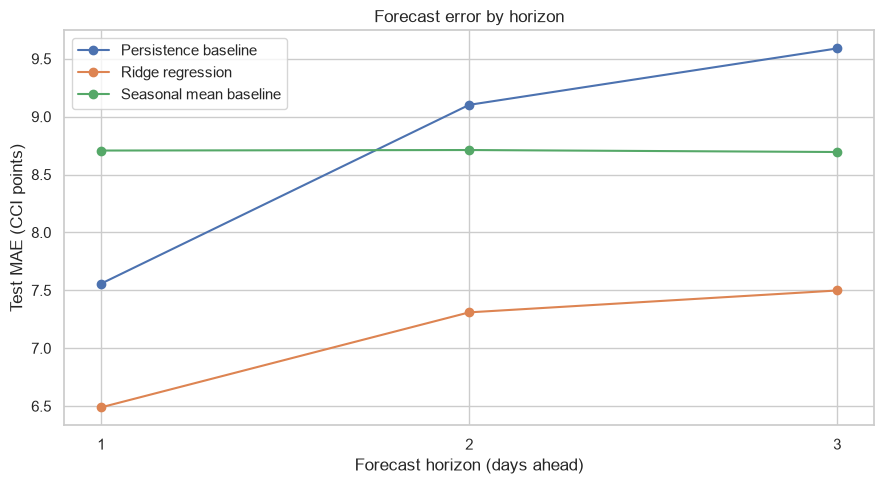

In [94]:
# Forecast skill decay: the same model gets harder as the horizon grows.
fig, ax = plt.subplots(figsize=(9, 5))

for name, group in results.groupby("model"):
    ax.plot(group["horizon"], group["mae"], marker="o", label=name)

ax.set_xticks(CCI_HORIZONS)
ax.set_xlabel("Forecast horizon (days ahead)")
ax.set_ylabel("Test MAE (CCI points)")
ax.set_title("Forecast error by horizon")
ax.legend()
plt.tight_layout()
plt.show()

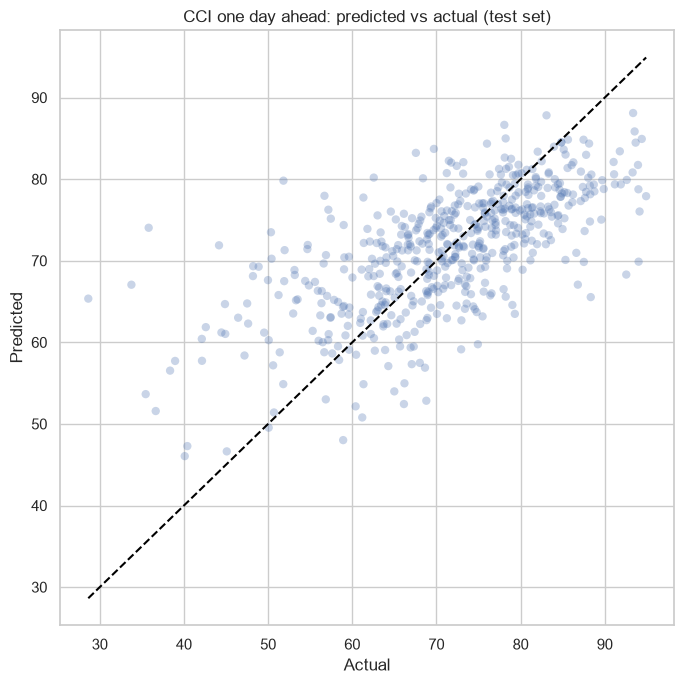

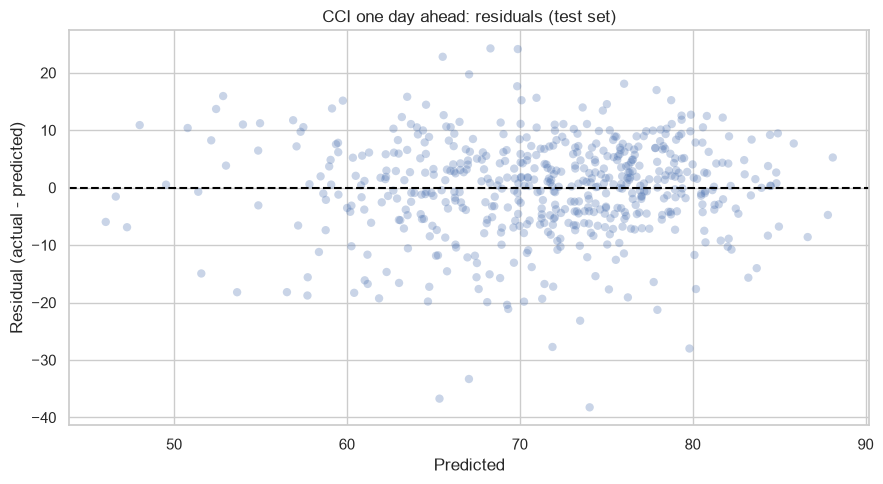

In [95]:
# Diagnostics for the one-day model.
d = datasets[1]
y_pred_h1 = models[1].predict(d["X_test"])

visualization.plot_predicted_vs_actual(
    d["y_test"], y_pred_h1, title="CCI one day ahead: predicted vs actual (test set)"
)
plt.show()

visualization.plot_residuals(
    d["y_test"], y_pred_h1, title="CCI one day ahead: residuals (test set)"
)
plt.show()

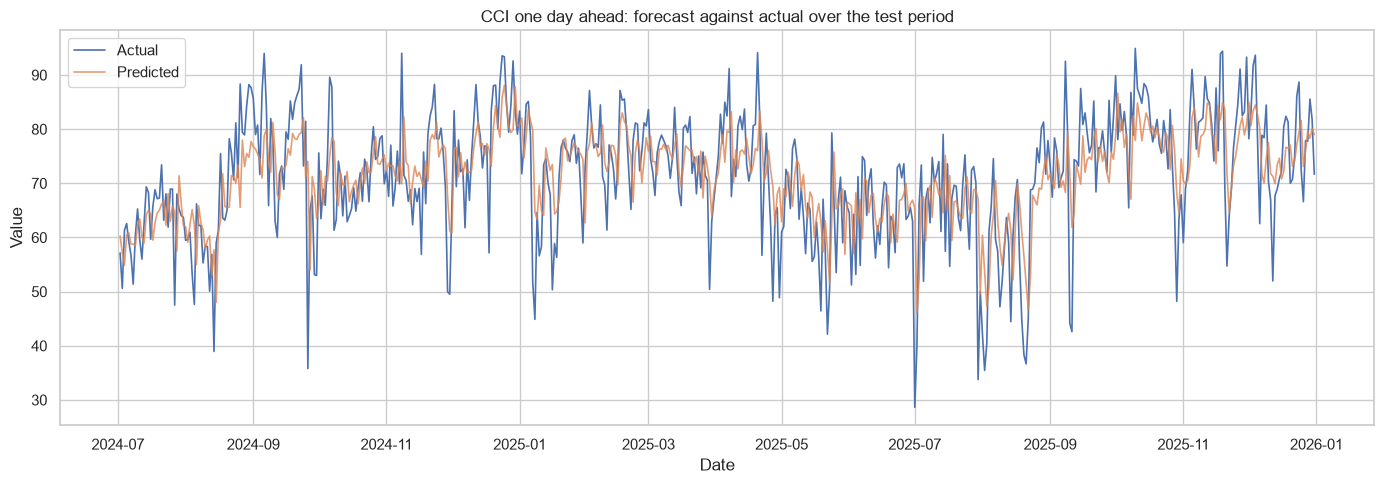

In [96]:
visualization.plot_forecast_timeline(
    d["test"]["target_date"], d["y_test"], y_pred_h1,
    title="CCI one day ahead: forecast against actual over the test period",
)
plt.show()

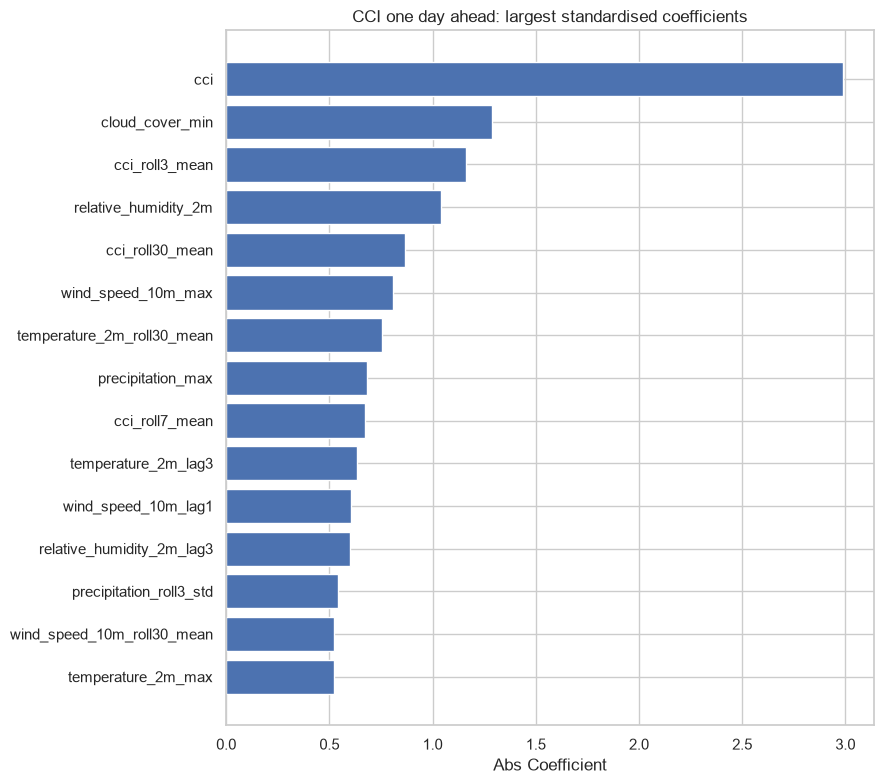

,feature,coefficient,abs_coefficient
0,cci,2.989,2.989
1,cloud_cover_min,-1.287,1.287
2,cci_roll3_mean,1.162,1.162
3,relative_humidity_2m,-1.043,1.043
4,cci_roll30_mean,0.865,0.865
5,wind_speed_10m_max,-0.807,0.807
6,temperature_2m_roll30_mean,0.754,0.754
7,precipitation_max,0.684,0.684
8,cci_roll7_mean,0.672,0.672
9,temperature_2m_lag3,0.636,0.636


In [97]:
# Which features does the model actually rely on? The fitted estimator is
# reached through the pipeline, and its coefficients are comparable because
# the pipeline standardised the inputs.
coefficients = importance.linear_coefficient_importance(
    models[1].named_steps["model"], feature_columns
)

visualization.plot_feature_importance(
    coefficients, value_column="abs_coefficient", top_n=15,
    title="CCI one day ahead: largest standardised coefficients",
)
plt.show()

coefficients.head(15).round(3)

In [98]:
# Permutation importance measures what the model relies on when
# generalising, computed on held-out data rather than the training set.
permutation = importance.permutation_feature_importance(
    models[1], d["X_test"], d["y_test"], n_repeats=10, random_state=RANDOM_STATE
)
permutation.head(15).round(4)

,feature,importance_mean,importance_std
0,cci,0.1871,0.0183
1,relative_humidity_2m,0.0378,0.0036
2,cci_roll3_mean,0.0363,0.0061
3,cloud_cover_min,0.0345,0.0036
4,cci_roll7_mean,0.0145,0.0033
5,cci_roll30_mean,0.0138,0.0038
6,precipitation_max,0.0104,0.0040
7,cci_lag3,0.0093,0.0027
8,temperature_2m_lag3,0.0090,0.0038
9,temperature_2m_roll30_mean,0.0080,0.0044


In [99]:
# Where does the model fail? Errors are examined against the conditions on
# the day being predicted, to test the expectations set in section C.
error_analysis = d["test"][["date", "target_date"]].copy()
error_analysis["actual"] = d["y_test"].to_numpy()
error_analysis["predicted"] = y_pred_h1
error_analysis["error"] = error_analysis["actual"] - error_analysis["predicted"]

# Conditions on the predicted day, joined back from the daily record.
conditions = daily.set_index("date")[["temperature_2m", "precipitation"]]
error_analysis = error_analysis.join(conditions, on="target_date")

wet = error_analysis["precipitation"] > 10
hot = error_analysis["temperature_2m"] > 25

print(f"MAE on all test days:      {error_analysis['error'].abs().mean():.2f}")
print(f"MAE on wet days (>10 mm):  {error_analysis.loc[wet, 'error'].abs().mean():.2f}  (n={wet.sum()})")
print(f"MAE on hot days (>25 C):   {error_analysis.loc[hot, 'error'].abs().mean():.2f}  (n={hot.sum()})")
print()
print("Largest over-predictions (model said comfortable, day was not):")
error_analysis.nsmallest(5, "error")[
    ["target_date", "actual", "predicted", "error", "precipitation"]
].round(1)

MAE on all test days:      6.49
MAE on wet days (>10 mm):  15.97  (n=44)
MAE on hot days (>25 C):   4.58  (n=24)

Largest over-predictions (model said comfortable, day was not):


,target_date,actual,predicted,error,precipitation
86,2024-09-26,35.8,74.0,-38.2,19.8
364,2025-07-01,28.6,65.4,-36.7,64.7
393,2025-07-30,33.8,67.1,-33.3,21.6
189,2025-01-07,51.8,79.8,-28.0,16.5
435,2025-09-10,44.2,71.9,-27.7,27.5


In [100]:
model_performance_explanations = """
The ridge model beats both baselines at every horizon. Test MAE is 6.49 CCI
points at one day, 7.31 at two and 7.50 at three, against a persistence
baseline of 7.56, 9.10 and 9.59 and a seasonal baseline of about 8.70 at
every horizon.

The two baselines fail in opposite and instructive ways. Persistence is
competitive at one day and collapses beyond it, posting a negative R squared
at two and three days, meaning that predicting "the same as today" is
actually worse than predicting the long-run average once you look more than
a day ahead. The seasonal baseline is flat across horizons, as it must be
since it ignores current conditions entirely, but its R squared of roughly
0.05 shows that the time of year alone explains very little day-to-day
variation. The model's value comes from combining the two sources: recent
conditions, which decay in usefulness, and seasonal position, which does not.

That combination is visible in the coefficients. At one day ahead the
dominant input is today's CCI by a wide margin, with a standardised
coefficient of 2.99 against 1.29 for the next feature, and permutation
importance of 0.187 against 0.038. By three days ahead the ranking has
changed: the thirty-day rolling mean of CCI overtakes today's value, and the
cyclical calendar features climb from around rank 16 to around rank 7. The
model shifts from persistence to climatology as the horizon lengthens,
which is exactly the behaviour meteorological forecasting shows and was not
imposed by hand.

Forecast skill decays with horizon, and R squared falls from 0.45 to 0.29 to
0.25. This is a property of the atmosphere rather than a deficiency in the
model, and it is the single most important thing to communicate to users:
the three-day figure is indicative where the one-day figure is dependable.

RMSE sits well above MAE at every horizon (8.54 against 6.49 at one day),
indicating a heavy-tailed error distribution — most days are forecast well
and a minority very badly. The error analysis locates that tail precisely.
On dry days MAE is 5.67 and on days with light rain 5.63, but on days with
more than 10 mm it is 15.97, nearly three times worse. On those wet days the
model over-predicts comfort 98% of the time, with a mean error of -15.8
points.

This is the predicted failure of a linear model on a clipped component, and
it is worth being clear that it is not a general bias. Overall mean error is
-0.14, essentially zero, because a small positive bias on the 504 dry days
offsets a large negative one on the 44 wet days. The model is not
systematically optimistic; it is systematically optimistic about rain
specifically, which is the more commercially damaging direction of error
identified in section A.

One expectation was not borne out. Hot days were anticipated to be a second
failure mode, given the inverted V in the temperature component, but MAE on
days above 25 C is 4.58, better than the overall average. Such days are both
rare and clustered in summer, when conditions are generally more predictable,
and the temperature component is apparently well enough approximated by the
linear fit across the range Sydney actually reaches.
"""

In [101]:
# Do not modify this code
print_tile(size="h3", key='model_performance_explanations', value=model_performance_explanations)

### J.5 Business Impact from Current Model Performance

In [102]:
# Translating error into the decision it affects: how often does the
# forecast land in the correct interpretation band?
bands = [0, 20, 40, 60, 80, 100]
band_labels = ["Very poor", "Poor", "Moderate", "Comfortable", "Excellent"]

for h in CCI_HORIZONS:
    dh = datasets[h]
    pred = models[h].predict(dh["X_test"])
    actual_band = pd.cut(dh["y_test"], bins=bands, labels=band_labels, right=False)
    predicted_band = pd.cut(pd.Series(pred, index=dh["y_test"].index),
                            bins=bands, labels=band_labels, right=False)
    agreement = (actual_band == predicted_band).mean()
    within_5 = (np.abs(dh["y_test"] - pred) <= 5).mean()
    print(f"horizon {h}:  correct comfort band {agreement:.1%}   "
          f"within 5 CCI points {within_5:.1%}")

horizon 1:  correct comfort band 63.3%   within 5 CCI points 48.9%
horizon 2:  correct comfort band 61.8%   within 5 CCI points 45.5%
horizon 3:  correct comfort band 61.9%   within 5 CCI points 43.2%


In [103]:
business_impacts_explanations = """
Translated into the decision it supports, the model places the forecast in
the correct comfort band on 63.3% of one-day-ahead test days, 61.8% at two
days and 61.9% at three. It lands within five CCI points of the truth on
48.9%, 45.5% and 43.2% of days respectively.

Band agreement is the more meaningful figure for an operator deciding
whether to run an outdoor event, because that decision is made on the band
rather than the exact number. Roughly two days in three are categorised
correctly, which supports advisory use but is not strong enough to
schedule against without human judgement. Notably, band agreement barely
degrades between one and three days even though numeric error grows
appreciably, because most of the additional error is absorbed within a
twenty-point band rather than crossing a boundary.

The errors that change decisions are those near a band boundary, where a
small numerical miss flips the recommendation. This argues for the deployed
service exposing the numeric prediction rather than only the band, so that a
value near a boundary is visibly near one.

The most consequential finding for the business is the behaviour on wet
days. The model over-predicts comfort on 98% of days receiving more than
10 mm of rain, by an average of nearly 16 CCI points — frequently enough to
move a day two full bands. This is precisely the failure identified in
section A as the expensive one: customers are brought outdoors into
conditions that were forecast as pleasant, refunds follow and trust erodes.
That it affects only 8% of test days is little comfort, because those are
the days on which a wrong answer costs the most.

The underlying cause is a mismatch between the metric optimised and the cost
borne. Squared error treats over- and under-prediction as equally bad, when
they are not. Three recommendations follow, in order of expected value.
First, and most urgently, the service should not be relied upon for outdoor
commitments when any rainfall is forecast, and the deployed API should be
documented accordingly. Second, a tree-based model should be evaluated, since
it can represent the clipped rain component directly and is likely to
recover much of this error. Third, a quantile or asymmetric loss variant
would let the service offer a deliberately conservative estimate where being
wrong in the optimistic direction is costly.

The model is suitable for advisory use with those caveats stated. It is not
suitable as a sole input to safety-critical decisions, for which the hazard
classification service is the appropriate tool.
"""

In [104]:
# Do not modify this code
print_tile(size="h3", key='business_impacts_explanations', value=business_impacts_explanations)

### J.6 Save Model Artefacts

In [105]:
# Each artefact bundles everything the API needs to reproduce a prediction:
# the fitted pipeline (scaler and model together), the recipe describing how
# to build the features, the exact feature order, and the measured
# performance for /model-metadata.
CCI_MODELS_DIR.mkdir(parents=True, exist_ok=True)

for h in CCI_HORIZONS:
    test_metrics = modeling.evaluate_regression(
        datasets[h]["y_test"], models[h].predict(datasets[h]["X_test"])
    )
    artefact = {
        "pipeline": models[h],
        "recipe": CCI_RECIPE,
        "feature_columns": feature_columns,
        "history_days": features.required_history_days(CCI_RECIPE),
        "target": "Climate Comfort Index",
        "horizon_days": h,
        "algorithm": "Ridge Regression",
        "alpha": best_alphas[h],
        "training_window": [CCI_TRAIN_START, VALIDATION_START],
        "metrics": test_metrics,
        "feature_importance": (
            importance.linear_coefficient_importance(
                models[h].named_steps["model"], feature_columns
            ).head(10).set_index("feature")["coefficient"].round(4).to_dict()
        ),
    }
    path = CCI_MODELS_DIR / f"cci_ridge_h{h}.joblib"
    joblib.dump(artefact, path)
    print(f"saved {path.name}  (test MAE {test_metrics['mae']:.2f})")

saved cci_ridge_h1.joblib  (test MAE 6.49)
saved cci_ridge_h2.joblib  (test MAE 7.31)
saved cci_ridge_h3.joblib  (test MAE 7.50)


## H. Project Outcomes

In [106]:
# Either 'Hypothesis Confirmed', 'Hypothesis Partially Confirmed' or
# 'Hypothesis Rejected'.
#
# Partially confirmed: the model beats both baselines at every horizon, but
# fails badly on wet days in the specific way a linear model was expected to.
experiment_outcome = "Hypothesis Partially Confirmed"

In [107]:
# Do not modify this code
print_tile(size="h2", key='experiment_outcomes_explanations', value=experiment_outcome)

In [108]:
experiment_results_explanations = """
The hypothesis was that a regularised linear model, given lagged weather,
rolling summaries and cyclical calendar features, could forecast the Climate
Comfort Index usefully at one to three days ahead. This is partially
confirmed. The model beats both the persistence and seasonal baselines at
every horizon, reducing MAE from 7.56 to 6.49 at one day and from 9.59 to
7.50 at three, so the feature set carries genuine predictive information
beyond either naive answer. It also fails in a specific and predictable
place: days with meaningful rainfall, where error nearly triples and the
model is optimistic 98% of the time.

Four insights came out of the experiment. First, the two naive baselines are
strong in complementary regimes and weak outside them — persistence at one
day, climatology at three — and the model's value lies in blending them
rather than in beating either outright. Second, that blending is visible in
the fitted coefficients, which shift from today's CCI at one day to the
thirty-day rolling mean and the calendar features at three, reproducing the
persistence-to-climatology transition known from meteorology without it
being imposed. Third, forecast skill decays measurably with horizon, and
this should be surfaced to users rather than hidden behind three
equally-presented numbers. Fourth, and most important for the business, the
average error badly understates the cost of the errors that occur: overall
bias is essentially zero only because a small optimism on dry days cancels a
large one on wet days.

One prediction was wrong and is worth recording. Hot days were expected to
be a second failure mode because the temperature component is non-linear,
but they were forecast better than average. The non-linearity is apparently
mild across the range Sydney actually reaches, which suggests the gain from
moving to a non-linear model will come almost entirely from the rain
component rather than the temperature one.

This is not a dead end and the next steps are clear, ranked by expected
uplift. First, a gradient boosted tree ensemble, which can represent the
clipped rain component directly and is the most likely route to removing the
wet-day error that dominates the loss. Second, rainfall-specific feature
engineering — a binary wet-day indicator, rolling counts of rain days, and
antecedent rainfall over longer windows — since millimetre totals whose
distribution is over half zeros are a poor input regardless of model. Third,
an asymmetric or quantile loss to align the objective with the business cost
of over-predicting comfort. The first two are expected to produce the
largest gains and should be run together as experiment two.

For deployment, the artefacts saved in section J.6 are sufficient to serve
the endpoint: each bundles the fitted model, its scaler, the feature order
and the measured test performance. The recommendation is to deploy this
baseline so the end-to-end service can be validated, then replace the model
artefacts once experiment two has been evaluated, since the API contract
does not change.
"""

In [109]:
# Do not modify this code
print_tile(size="h2", key='experiment_results_explanations', value=experiment_results_explanations)